# Tekstil Üretiminde Ekip Verimliliği

Amaç, üretim ekiplerinin verimliliğini incelemek ve hedeflenen verimlilik, fazla mesai, prim ve çalışan sayısı gibi bilgilerle gerçekleşen verimliliği tahmin etmek. Hedefi karşılama oranı bölümleri karşılaştırmak için kullanıldı. Modelleme `model_configuration.ipynb` dosyasında yapıldı.

Veri hazır CSV olarak UCI'dan alındı. Her satır bir ekip, bölüm ve gün kaydı. Veri 1 Ocak–11 Mart 2015 arasındaki 59 kayıt gününü kapsıyor.

Kaynak: *Productivity Prediction of Garment Employees* [Veri seti]. (2020). UCI Machine Learning Repository. [DOI](https://doi.org/10.24432/C51S6D) · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("./data/raw/garments_worker_productivity.csv")
df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: float64(6), 

## Veri hazırlama

In [4]:
for column in ["department", "quarter", "day", "team"]:
    print(f"{column}: {df[column].unique()}")

department: <StringArray>
['sweing', 'finishing ', 'finishing']
Length: 3, dtype: str
quarter: <StringArray>
['Quarter1', 'Quarter2', 'Quarter3', 'Quarter4', 'Quarter5']
Length: 5, dtype: str
day: <StringArray>
['Thursday', 'Saturday', 'Sunday', 'Monday', 'Tuesday', 'Wednesday']
Length: 6, dtype: str
team: [ 8  1 11 12  6  7  2  3  9 10  5  4]


In [5]:
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["department"] = df["department"].str.strip().replace({"sweing": "sewing"})
df = df.sort_values("date", kind="stable").reset_index(drop=True)

print("Tekrarlanan satır:", df.duplicated().sum())

Tekrarlanan satır: 0


In [6]:
missing = pd.DataFrame({
    "Eksik kayıt": df.isna().sum(),
    "Eksik oranı (%)": df.isna().mean().mul(100).round(1),
})
missing.loc[missing["Eksik kayıt"] > 0]

,Eksik kayıt,Eksik oranı (%)
wip,506,42.3


In [7]:
df.groupby("department")["wip"].agg(toplam="size", dolu="count")

,toplam,dolu
department,,
finishing,506,0
sewing,691,691


`wip` kayıtlarının %42,3’ü eksik. 506 eksik kaydın tamamı finishing bölümünde, sewing bölümünde ise tüm değerler dolu. Bölümler arası analizde `wip` kullanılmadı ve eksikler boş bırakıldı. Kategori adları ve ölçümlerin özgün ölçekleri korundu.

In [8]:
numeric_df = df.select_dtypes(include="number").drop(columns=["team"])
numeric_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
targeted_productivity,1197.0,0.73,0.10,0.07,0.70,0.75,0.80,0.80
smv,1197.0,15.06,10.94,2.90,3.94,15.26,24.26,54.56
wip,691.0,1190.47,1837.46,7.00,774.50,1039.00,1252.50,23122.00
over_time,1197.0,4567.46,3348.82,0.00,1440.00,3960.00,6960.00,25920.00
incentive,1197.0,38.21,160.18,0.00,0.00,0.00,50.00,3600.00
idle_time,1197.0,0.73,12.71,0.00,0.00,0.00,0.00,300.00
idle_men,1197.0,0.37,3.27,0.00,0.00,0.00,0.00,45.00
no_of_style_change,1197.0,0.15,0.43,0.00,0.00,0.00,0.00,2.00
no_of_workers,1197.0,34.61,22.20,2.00,9.00,34.00,57.00,89.00
actual_productivity,1197.0,0.74,0.17,0.23,0.65,0.77,0.85,1.12


In [9]:
productivity = df["actual_productivity"]
q1, q3 = productivity.quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print(f"IQR sınırları: {lower:.3f} – {upper:.3f}")
print("Sınır dışındaki kayıt:", ((productivity < lower) | (productivity > upper)).sum())
print("1'in üzerindeki kayıt:", productivity.gt(1).sum())

IQR sınırları: 0.350 – 1.150
Sınır dışındaki kayıt: 54
1'in üzerindeki kayıt: 37


IQR yöntemine göre 54 kayıt alt sınırın altında. Düşük verimlilik gözlemleri proje sorusu için önemli olduğu için tutuldu. 1’i aşan 37 kayıt da kaynak değerleriyle korundu.

## Keşifsel veri analizi

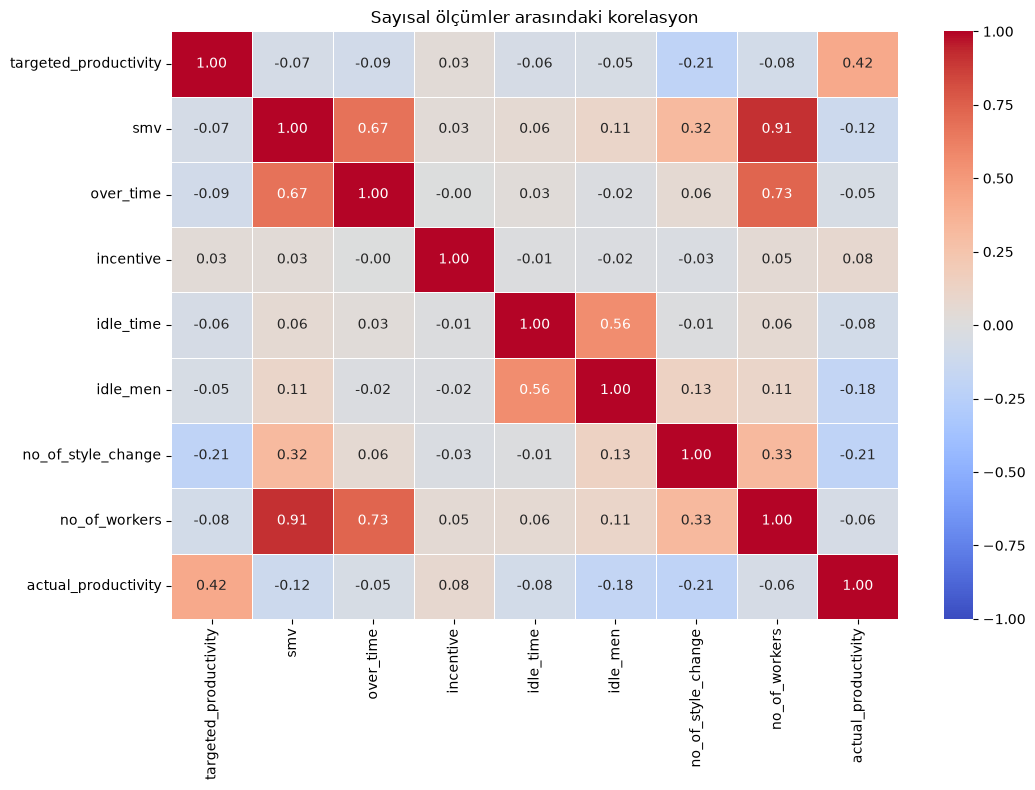

In [10]:
corr = numeric_df.drop(columns=["wip"]).corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", linewidths=.5)
plt.title("Sayısal ölçümler arasındaki korelasyon")
plt.tight_layout()
plt.show()

Gerçekleşen verimlilikle en yüksek doğrusal ilişki hedeflenen verimlilikte (r = 0,42). Fazla mesaiyle ilişki bu kayıtlarda sıfıra yakın (r = −0,05).

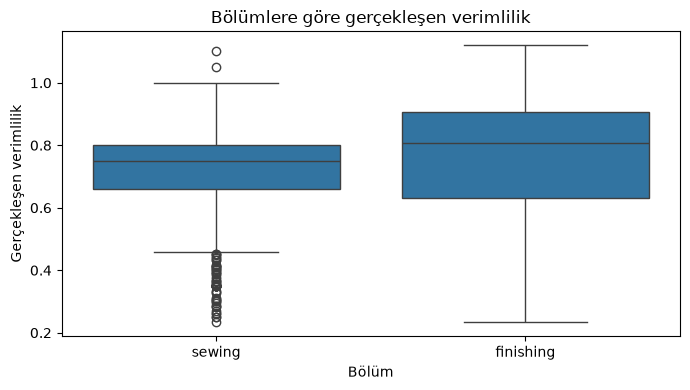

In [11]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="department", y="actual_productivity")
plt.title("Bölümlere göre gerçekleşen verimlilik")
plt.xlabel("Bölüm")
plt.ylabel("Gerçekleşen verimlilik")
plt.tight_layout()
plt.show()

Finishing bölümünde medyan gerçekleşen verimlilik 0,81, sewing bölümünde 0,75. Her iki bölümde de medyanın belirgin altında kalan kayıtlar var.

In [12]:
df["productivity_gap"] = df["actual_productivity"] - df["targeted_productivity"]
df["met_target"] = df["productivity_gap"] >= 0

summary = df.groupby("department").agg(
    kayit=("met_target", "size"),
    hedefi_karsilayan=("met_target", "sum"),
    hedefi_karsilama_orani=("met_target", "mean"),
)
summary["hedefi_karsilama_orani"] *= 100
summary.round(1)

,kayit,hedefi_karsilayan,hedefi_karsilama_orani
department,,,
finishing,506,302,59.7
sewing,691,573,82.9


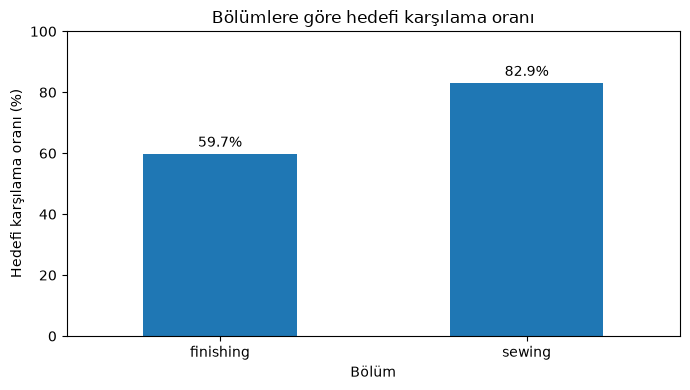

In [13]:
ax = summary["hedefi_karsilama_orani"].plot.bar(figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set(title="Bölümlere göre hedefi karşılama oranı", xlabel="Bölüm",
       ylabel="Hedefi karşılama oranı (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

Hedefi karşılama oranı finishing bölümünde %59,7, sewing bölümünde %82,9. `productivity_gap` gerçekleşen değerden hedef çıkarılarak hesaplandı. `met_target` hedefin karşılanıp karşılanmadığını gösteriyor.

## Sonuç

Hedef altında kalan ekip-günlerini incelemeye finishing bölümünden başlanabilir. Veri yaklaşık iki aylık bir dönemi kapsıyor. Daha uzun süreli kayıtlar ve ürün tipi bilgisiyle bölüm farkı yeniden incelenebilir.

In [14]:
output_path = Path("./data/processed/garments_worker_productivity_clean.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False)
print(f"{len(df)} kayıt kaydedildi: {output_path}")

1197 kayıt kaydedildi: data\processed\garments_worker_productivity_clean.csv
